# LogiStream intel: a temporal GRU and an XGBoost-style booster, explained

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SachmanChadhaa/Logi_Stream/blob/main/notebooks/LogiStream_GRU_XGBoost.ipynb)

LogiStream is a Socratic coding tutor. While a student works, every **event**
(a code run, a chat message, a screen observation, a long silence) becomes a
30-number **feature vector**. Two small models read that stream:

| Model | Question it answers | Where it lives in the repo |
|---|---|---|
| **GRU** (recurrent network) | *How is this student doing over time?* progressing / stuck / thrashing / idle | `intel/src/gru.rs` (Rust, burn) |
| **Gradient-boosted trees** (XGBoost-style) | *Which of the rules' candidate causes is most likely the real one?* | `intel/src/booster.rs` (pure Rust) |

This notebook rebuilds both **in Python** so every step can be read, run and
changed: the feature schema, the synthetic training data, the GRU equations and
training loop, the boosting maths (with a from-scratch booster checked against
real `xgboost`), the evaluation, and how the results are used in production.

> **Honesty first.** All labels here are produced by scripted scenarios, so the
> models can only relearn those scripts. In LogiStream they are labelled
> **"synthetic-trained v0, advisory, unvalidated"**, their scores are never
> called probabilities, and the booster runs in **shadow mode** (it is shown but
> never allowed to reorder the rules) because it does not beat the rules on
> held-out data. The same honesty applies to every number in this notebook.

**Contents**
1. Setup
2. The system in one picture
3. Feature schema v1 (the 30 numbers)
4. Synthetic sessions (training data)
5. The GRU: equations, model, truncated BPTT, evaluation
6. Gradient boosting: the maths, a from-scratch booster, real XGBoost
7. Shadow mode: when may a model override the rules?
8. How this maps to the Rust code, and what is new

## 1. Setup

Everything used here is preinstalled on Colab (`numpy`, `torch`, `xgboost`,
`scikit-learn`, `matplotlib`). The seed makes every run identical.

In [1]:
import importlib, subprocess, sys
for pkg in ("xgboost", "sklearn", "torch"):
    if importlib.util.find_spec(pkg) is None:   # only outside Colab
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "scikit-learn" if pkg == "sklearn" else pkg], check=True)

import math, random
import numpy as np
import torch, torch.nn as nn
import xgboost as xgb
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
from sklearn.decomposition import PCA

SEED = 7
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("torch", torch.__version__, "| xgboost", xgb.__version__, "| numpy", np.__version__)

torch 2.14.1+cpu | xgboost 3.2.0 | numpy 2.4.6


## 2. The system in one picture

A small helper draws box-and-arrow diagrams with matplotlib (Colab does not
render Mermaid), so the diagrams below are plain code you can edit.

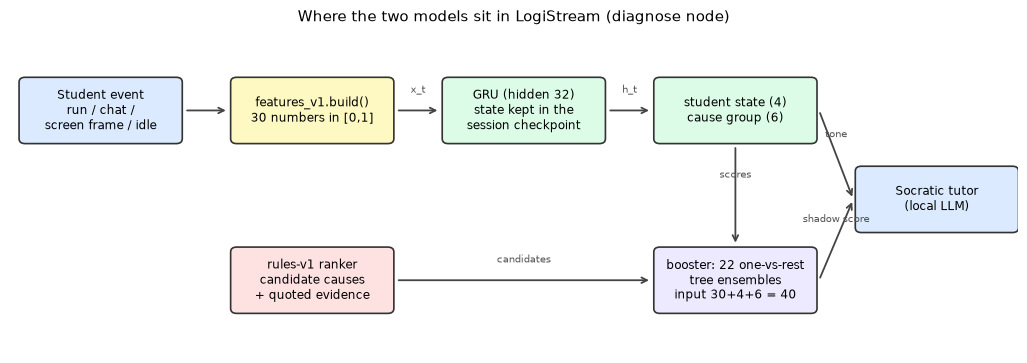

In [2]:
def diagram(boxes, arrows, size=(13, 4.2), title=None):
    """boxes: {name: (x, y, text, colour)} in a 0..100 x 0..40 canvas;
    arrows: [(from, to, label)]."""
    fig, ax = plt.subplots(figsize=size)
    ax.set_xlim(0, 100); ax.set_ylim(0, 40); ax.axis("off")
    W, H = 15, 7
    for name, (x, y, text, colour) in boxes.items():
        ax.add_patch(FancyBboxPatch((x - W / 2, y - H / 2), W, H, boxstyle="round,pad=0.6",
                                    fc=colour, ec="#333", lw=1.2))
        ax.text(x, y, text, ha="center", va="center", fontsize=8.5, wrap=True)
    for a, b, label in arrows:
        (x1, y1), (x2, y2) = boxes[a][:2], boxes[b][:2]
        ax.annotate("", xy=(x2 - (W / 2 + 0.8) * np.sign(x2 - x1) if x1 != x2 else x2,
                            y2 - (H / 2 + 0.8) * np.sign(y2 - y1) if x1 == x2 else y2),
                    xytext=(x1 + (W / 2 + 0.8) * np.sign(x2 - x1) if x1 != x2 else x1,
                            y1 + (H / 2 + 0.8) * np.sign(y2 - y1) if x1 == x2 else y1),
                    arrowprops=dict(arrowstyle="->", lw=1.3, color="#444"))
        if label:
            ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 2.2, label, ha="center", fontsize=7.5, color="#555")
    if title:
        ax.set_title(title, fontsize=11)
    plt.show()

B, G, Y, P, R = "#dbeafe", "#dcfce7", "#fef9c3", "#ede9fe", "#fee2e2"
diagram(
    {"ev":   (9, 30, "Student event\nrun / chat /\nscreen frame / idle", B),
     "fx":   (30, 30, "features_v1.build()\n30 numbers in [0,1]", Y),
     "gru":  (51, 30, "GRU (hidden 32)\nstate kept in the\nsession checkpoint", G),
     "out":  (72, 30, "student state (4)\ncause group (6)", G),
     "rules":(30, 9, "rules-v1 ranker\ncandidate causes\n+ quoted evidence", R),
     "bst":  (72, 9, "booster: 22 one-vs-rest\ntree ensembles\ninput 30+4+6 = 40", P),
     "tut":  (92, 19, "Socratic tutor\n(local LLM)", B)},
    [("ev", "fx", ""), ("fx", "gru", "x_t"), ("gru", "out", "h_t"), ("out", "bst", "scores"),
     ("rules", "bst", "candidates"), ("bst", "tut", "shadow score"), ("out", "tut", "tone")],
    title="Where the two models sit in LogiStream (diagnose node)")

**Reading the picture.** The deterministic **rules ranker** always produces the
candidate causes, each with quoted evidence (an error line, a failing test).
The GRU summarises *history* into a 32-number hidden state carried from event to
event. The booster scores the rules' own candidates using the event's features
plus the GRU's outputs. The tutor always receives the rules' order; booster
scores ride along for display unless the model is promoted (section 7).

## 3. Feature schema v1: the 30 numbers

Every event becomes the same 30-slot vector (`docs/feature_schema_v1.md`; the
Python and Rust builders are checked against one golden vector in CI). All slots
are in `[0, 1]`: one-hot groups, ratios, and counts squashed with a cap.

In [3]:
FEATURES = [
    "lang_python", "err_none", "err_compile", "err_runtime", "err_failing_test", "err_timeout",
    "has_error_line", "exception_known", "pass_ratio", "n_tests_norm", "stdout_empty_on_fail",
    "format_only_mismatch", "edit_size_norm", "changed_lines_norm", "code_unchanged",
    "dt_since_last_norm", "attempt_norm", "same_bucket_streak_norm", "recent_fail_rate",
    "stage_custom", "event_run", "event_chat", "event_observation", "event_idle",
    "vlm_error_visible", "vlm_editing", "vlm_terminal", "vlm_offtask",
    "loop_nesting_norm", "has_while_true"]
IDX = {f: i for i, f in enumerate(FEATURES)}
DIM = len(FEATURES)
STATES = ["progressing", "stuck", "thrashing", "idle"]
GROUPS = ["syntax", "runtime", "performance", "output", "logic", "unverified"]
CAUSES = ["syntax", "undefined-name", "missing-key", "index-out-of-range", "type-mismatch", "uses-none",
          "missing-attribute", "bad-conversion", "division-by-zero", "unbounded-recursion",
          "reads-too-much-input", "module-unavailable", "runtime-crash", "too-slow",
          "possible-infinite-loop", "prints-nothing", "returns-none", "output-format", "extra-output",
          "logic-wrong-on-case", "unchanged-code", "unverified"]
RUNTIME = CAUSES[1:13]
def group_of(cause):
    c = CAUSES[cause]
    if c == "syntax": return 0
    if c in RUNTIME: return 1
    if c in ("too-slow", "possible-infinite-loop"): return 2
    if c in ("prints-nothing", "returns-none", "output-format", "extra-output"): return 3
    if c in ("logic-wrong-on-case", "unchanged-code"): return 4
    return 5

groups = {"language": FEATURES[0:1], "error category (one-hot)": FEATURES[1:6],
          "error evidence": FEATURES[6:12], "editing behaviour": FEATURES[12:15],
          "timing & history": FEATURES[15:20], "event kind (one-hot)": FEATURES[20:24],
          "screen observer tags": FEATURES[24:28], "code shape": FEATURES[28:30]}
for g, fs in groups.items():
    print(f"{g:28s} {', '.join(fs)}")
print(f"\nDIM = {DIM}, states = {STATES}, cause groups = {GROUPS}, causes = {len(CAUSES)}")

language                     lang_python
error category (one-hot)     err_none, err_compile, err_runtime, err_failing_test, err_timeout
error evidence               has_error_line, exception_known, pass_ratio, n_tests_norm, stdout_empty_on_fail, format_only_mismatch
editing behaviour            edit_size_norm, changed_lines_norm, code_unchanged
timing & history             dt_since_last_norm, attempt_norm, same_bucket_streak_norm, recent_fail_rate, stage_custom
event kind (one-hot)         event_run, event_chat, event_observation, event_idle
screen observer tags         vlm_error_visible, vlm_editing, vlm_terminal, vlm_offtask
code shape                   loop_nesting_norm, has_while_true

DIM = 30, states = ['progressing', 'stuck', 'thrashing', 'idle'], cause groups = ['syntax', 'runtime', 'performance', 'output', 'logic', 'unverified'], causes = 22


## 4. Synthetic sessions (training data)

There are no real, consented student sessions yet, so training data is
**scripted**. Five scenario families mirror `intel/src/synth.rs`:

| Family | What the script does | State label |
|---|---|---|
| progressing | steady runs, moderate edits, errors resolve, ends accepted | progressing |
| stuck | the same failure run after run, tiny or no edits, slow | stuck (after the 2nd repeat) |
| thrashing | rapid runs, big random edits, causes jump around | thrashing |
| idle | long silences, chat, off-task screen observations | idle |
| recovering | stuck for a while, then a real fix | stuck → progressing |

Two details matter for learning. (1) The *state* often depends on history (being
stuck means *repeating*), which is what a recurrent model is for. (2) Each failed
run records the **candidate causes the rules would offer** and their order, so
the booster and the rules baseline are scored on exactly the same choice.

In [4]:
RULE_WEIGHT = {"syntax": 0.95, "possible-infinite-loop": 0.75, "prints-nothing": 0.85, "returns-none": 0.85,
               "output-format": 0.8, "extra-output": 0.8, "logic-wrong-on-case": 0.6, "unverified": 0.6,
               "unchanged-code": 0.4}
def rule_weight(cause, loop_nesting):
    c = CAUSES[cause]
    if c == "too-slow":
        return 0.7 if loop_nesting >= 0.66 else 0.5
    return RULE_WEIGHT.get(c, 0.9)          # runtime exceptions read straight from stderr

def pick_cause(rng, category):
    """category: 1 compile, 2 runtime, 3 failing test, 4 timeout -> (cause, evidence flags)."""
    ev = dict(stdout_empty=False, format_only=False, loops=0.33, while_true=False)
    if category == 1: return CAUSES.index("syntax"), ev | dict(loops=0.0)
    if category == 2: return CAUSES.index(rng.choice(RUNTIME)), ev
    if category == 4:
        if rng.random() < 0.3: return CAUSES.index("possible-infinite-loop"), ev | dict(while_true=True)
        return CAUSES.index("too-slow"), ev | dict(loops=0.66 if rng.random() < 0.85 else 0.33)
    r = rng.random()                          # failing test: the observable flag is right 85% of the time
    if r < 0.2:
        c = "prints-nothing" if rng.random() < 0.85 else "logic-wrong-on-case"
        return CAUSES.index(c), ev | dict(stdout_empty=True)
    if r < 0.35:
        c = "output-format" if rng.random() < 0.85 else "logic-wrong-on-case"
        return CAUSES.index(c), ev | dict(format_only=True)
    if r < 0.45:                              # the rules see the output text; the features do not
        return CAUSES.index(rng.choice(["returns-none", "extra-output"])), ev
    return CAUSES.index("logic-wrong-on-case"), ev

def rules_candidates(category, cause, ev, unchanged):
    c = CAUSES.index
    if category == 1: v = [c("syntax")]
    elif category == 2: v = [cause]
    elif category == 4: v = ([c("possible-infinite-loop")] if ev["while_true"] else []) + [c("too-slow")]
    else:
        v = []
        if ev["stdout_empty"]: v.append(c("prints-nothing"))
        if CAUSES[cause] == "returns-none": v.append(cause)
        if ev["format_only"]: v.append(c("output-format"))
        if CAUSES[cause] == "extra-output": v.append(cause)
        v.append(c("logic-wrong-on-case"))
    if unchanged and c("unchanged-code") not in v: v.append(c("unchanged-code"))
    return v[:3]                             # the truth can fall off the end: a real failure mode

In [5]:
def session(rng, family, sid):
    """One scripted session -> list of events (x, state, group, cause, candidates, rules_order)."""
    n = rng.randint(8, 16)
    events, streak, last_cat, attempts, fails, runs = [], 0, None, 0, 0, 0
    stuck_cat, stuck_cause = rng.choice([2, 3, 4]), None
    flip = rng.randint(n // 3, 2 * n // 3)                     # recovering: when the fix lands
    group = 5
    for t in range(n):
        phase = family if family != "recovering" else ("stuck" if t < flip else "progressing")
        kind = "run"
        if phase == "idle":
            kind = rng.choice(["chat", "observation", "idle", "idle", "run"])
        elif rng.random() < 0.15:
            kind = rng.choice(["chat", "observation"])
        x = np.zeros(DIM, np.float32)
        x[IDX["lang_python"]] = 1; x[IDX["stage_custom"]] = float(sid % 2)
        x[IDX["event_" + kind]] = 1
        dt = {"progressing": (0.2, 0.45), "stuck": (0.45, 0.8), "thrashing": (0.02, 0.15),
              "idle": (0.75, 1.0)}[phase]
        x[IDX["dt_since_last_norm"]] = rng.uniform(*dt)
        cause, cands, order = None, [], []
        if kind == "run":
            runs += 1; attempts += 1
            if phase == "progressing":
                cat = 0 if t >= n - 2 or rng.random() < t / n * 0.6 else rng.choice([1, 2, 3, 3, 4])
                changed = rng.uniform(0.15, 0.5)
            elif phase == "stuck":
                cat = stuck_cat; changed = 0.0 if rng.random() < 0.5 else rng.uniform(0.0, 0.06)
            else:                                               # thrashing / idle
                cat = rng.choice([1, 2, 3, 4, 0]); changed = rng.uniform(0.55, 1.0) if phase == "thrashing" else rng.uniform(0.0, 0.3)
            unchanged = changed == 0.0
            streak = streak + 1 if cat == last_cat else 0; last_cat = cat
            fails += cat != 0
            x[IDX["err_none"] + cat] = 1
            x[IDX["edit_size_norm"]] = changed; x[IDX["changed_lines_norm"]] = min(1, changed * 1.2)
            x[IDX["code_unchanged"]] = float(unchanged)
            x[IDX["pass_ratio"]] = 1.0 if cat == 0 else (rng.uniform(0, 0.8) if cat == 3 else 0.0)
            x[IDX["n_tests_norm"]] = 0.25
            if cat:
                if phase == "stuck" and stuck_cause is not None:
                    cause, ev = stuck_cause
                else:
                    cause, ev = pick_cause(rng, cat)
                    if phase == "stuck": stuck_cause = (cause, ev)
                x[IDX["has_error_line"]] = float(cat == 2); x[IDX["exception_known"]] = float(cat in (1, 2))
                x[IDX["stdout_empty_on_fail"]] = float(ev["stdout_empty"])
                x[IDX["format_only_mismatch"]] = float(ev["format_only"])
                x[IDX["loop_nesting_norm"]] = ev["loops"]; x[IDX["has_while_true"]] = float(ev["while_true"])
                cands = rules_candidates(cat, cause, ev, unchanged)
                order = sorted(cands, key=lambda k: -rule_weight(k, ev["loops"]))
                group = group_of(cause)
            else:
                group = 5 if phase == "idle" else group
        elif kind == "observation":
            x[IDX["vlm_offtask"]] = float(phase == "idle" or rng.random() < 0.2)
            x[IDX["vlm_editing"]] = float(not x[IDX["vlm_offtask"]])
            x[IDX["vlm_error_visible"]] = float(last_cat not in (None, 0) and rng.random() < 0.5)
        x[IDX["attempt_norm"]] = min(1, attempts / 20)
        x[IDX["same_bucket_streak_norm"]] = min(1, streak / 5)
        x[IDX["recent_fail_rate"]] = fails / max(1, runs)
        state = {"progressing": 0, "stuck": 1, "thrashing": 2, "idle": 3}[phase]
        if phase == "stuck" and streak < 2 and family == "stuck":
            state = 0                                            # not stuck yet: it takes repetition
        events.append(dict(x=x, state=state, group=group, cause=cause, cands=cands, order=order))
    return events

rng = random.Random(SEED)
FAMILIES = ["progressing", "stuck", "thrashing", "idle", "recovering"]
sequences = []
for sid in range(1500):
    fam = FAMILIES[sid % 5]
    sequences.append(dict(id=sid, family=fam, events=session(rng, fam, sid)))
# split by scenario GROUP, never by event: every 5th group of 5 sequences is held out,
# so no test event has a sibling event from the same session in training
train = [s for s in sequences if (s["id"] // 5) % 5 != 0]
test = [s for s in sequences if (s["id"] // 5) % 5 == 0]
n_ev = sum(len(s["events"]) for s in sequences)
print(f"{len(sequences)} sessions, {n_ev} events | train {len(train)} / test {len(test)} sessions")

1500 sessions, 18069 events | train 1200 / test 300 sessions


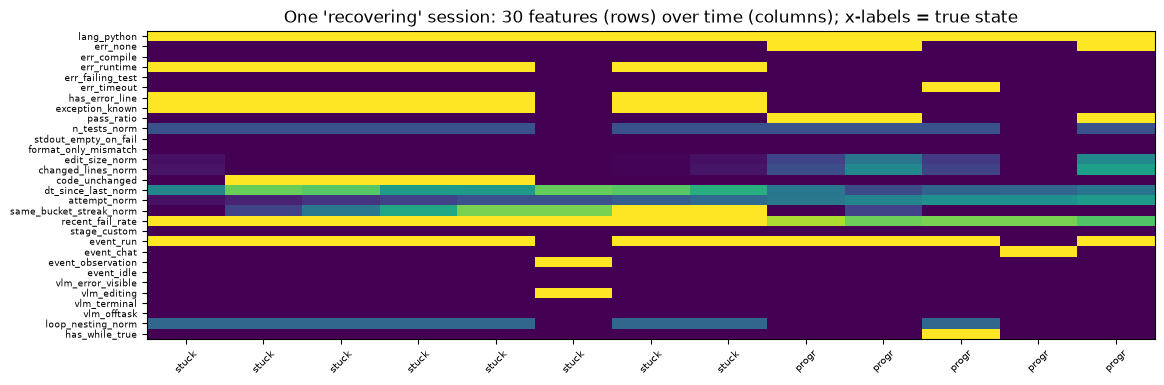

In [6]:
s = next(q for q in sequences if q["family"] == "recovering")
M = np.stack([e["x"] for e in s["events"]])
fig, ax = plt.subplots(figsize=(13, 4))
ax.imshow(M.T, aspect="auto", cmap="viridis")
ax.set_yticks(range(DIM)); ax.set_yticklabels(FEATURES, fontsize=6.5)
ax.set_xticks(range(len(M))); ax.set_xticklabels([STATES[e["state"]][:5] for e in s["events"]], fontsize=7, rotation=45)
ax.set_title("One 'recovering' session: 30 features (rows) over time (columns); x-labels = true state")
plt.show()

## 5. The GRU

### 5.1 Why a recurrent model?
"Stuck" is not visible in one event: it is *the same failure, again, with tiny
edits, getting slower*. A GRU keeps a **hidden state** $h_t$ (32 numbers) that
summarises everything seen so far in the session. LogiStream stores $h_t$ in the
session checkpoint, so the next event (seconds or hours later) continues from it.

### 5.2 The equations (one step)
For input $x_t \in \mathbb{R}^{30}$ and previous state $h_{t-1} \in \mathbb{R}^{32}$:

$$
\begin{aligned}
z_t &= \sigma(W_z x_t + U_z h_{t-1} + b_z) &&\text{update gate: how much to rewrite}\\
r_t &= \sigma(W_r x_t + U_r h_{t-1} + b_r) &&\text{reset gate: how much history feeds the candidate}\\
\tilde h_t &= \tanh(W_h x_t + U_h (r_t \odot h_{t-1}) + b_h) &&\text{candidate new state}\\
h_t &= (1 - z_t) \odot h_{t-1} + z_t \odot \tilde h_t &&\text{blend old and new}
\end{aligned}
$$

Two linear **heads** read $h_t$: student state (4 logits) and cause group
(6 logits). Training minimises the sum of two cross-entropies.

### 5.3 Truncated back-propagation through time (window 8)
Sessions are cut into windows of 8 events. The hidden state flows from one
window into the next but is **detached**, so gradients never cross a window
boundary: memory stays bounded and training stays stable on long sessions,
exactly like `intel/src/gru.rs`.

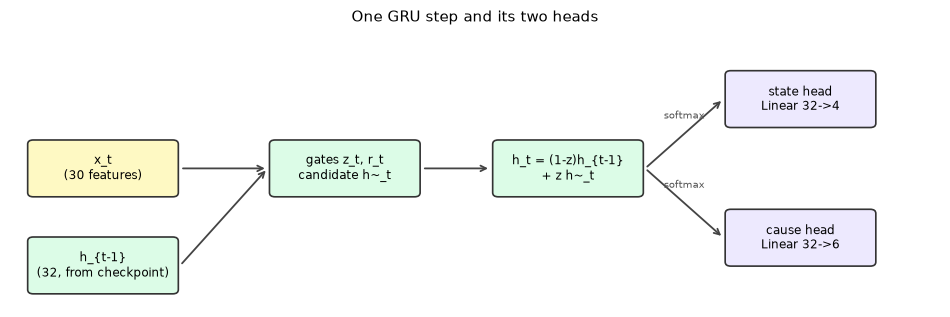

In [7]:
diagram(
    {"x":   (10, 20, "x_t\n(30 features)", Y),
     "h0":  (10, 6, "h_{t-1}\n(32, from checkpoint)", G),
     "g":   (36, 20, "gates z_t, r_t\ncandidate h~_t", G),
     "h":   (60, 20, "h_t = (1-z)h_{t-1}\n+ z h~_t", G),
     "s":   (85, 30, "state head\nLinear 32->4", P),
     "c":   (85, 10, "cause head\nLinear 32->6", P)},
    [("x", "g", ""), ("h0", "g", ""), ("g", "h", ""), ("h", "s", "softmax"), ("h", "c", "softmax")],
    size=(12, 3.6), title="One GRU step and its two heads")

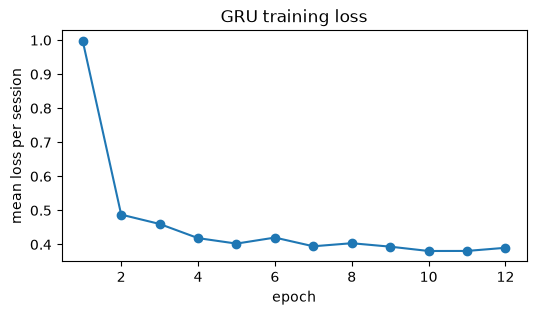

In [8]:
class TemporalGRU(nn.Module):
    """30 -> GRU(32) -> (state logits 4, cause-group logits 6). Mirrors intel/src/gru.rs."""
    def __init__(self, dim=DIM, hidden=32):
        super().__init__()
        self.gru = nn.GRU(dim, hidden, batch_first=True)
        self.state_head = nn.Linear(hidden, len(STATES))
        self.cause_head = nn.Linear(hidden, len(GROUPS))
    def forward(self, x, h0=None):                 # x: [batch, time, 30]
        hs, h = self.gru(x, h0)                     # hs: every step's hidden state
        return hs, self.state_head(hs), self.cause_head(hs), h

def tensors(seq):
    X = torch.tensor(np.stack([e["x"] for e in seq["events"]]))[None]
    ys = torch.tensor([e["state"] for e in seq["events"]])
    yg = torch.tensor([e["group"] for e in seq["events"]])
    return X, ys, yg

model = TemporalGRU()
opt = torch.optim.Adam(model.parameters(), lr=1e-2)
ce = nn.CrossEntropyLoss()
WINDOW, EPOCHS = 8, 12
losses = []
for epoch in range(EPOCHS):
    random.Random(epoch).shuffle(train)
    total = 0.0
    for seq in train:
        X, ys, yg = tensors(seq)
        h = None
        for a in range(0, X.shape[1], WINDOW):               # truncated BPTT
            _, ls, lg, h = model(X[:, a:a + WINDOW], h)
            loss = ce(ls[0], ys[a:a + WINDOW]) + ce(lg[0], yg[a:a + WINDOW])
            opt.zero_grad(); loss.backward(); opt.step()
            h = h.detach()                                    # the boundary: no gradient flows back past here
            total += loss.item()
    losses.append(total / len(train))
plt.figure(figsize=(6, 3)); plt.plot(range(1, EPOCHS + 1), losses, marker="o")
plt.xlabel("epoch"); plt.ylabel("mean loss per session"); plt.title("GRU training loss"); plt.show()

### 5.4 Evaluation against a hand-written baseline
A model is only interesting if it beats something simple. The baseline below is
the kind of rule a teacher would write from one event: long silence → idle,
repeating with no edit → stuck, fast big edits → thrashing, else progressing.

held-out events: 3644
heuristic  accuracy 0.893  macro-F1 0.893
GRU        accuracy 0.962  macro-F1 0.967


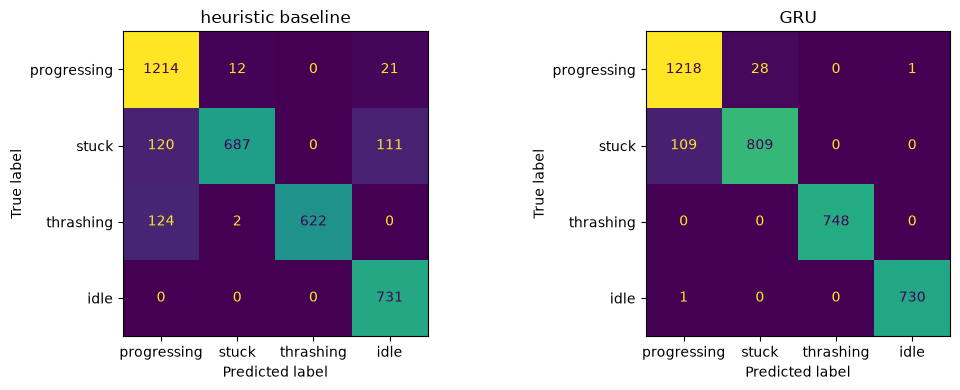

In [9]:
def heuristic_state(x):
    if x[IDX["dt_since_last_norm"]] > 0.75 or x[IDX["event_idle"]]: return 3
    if x[IDX["same_bucket_streak_norm"]] >= 0.4 and x[IDX["edit_size_norm"]] < 0.1: return 1
    if x[IDX["dt_since_last_norm"]] < 0.15 and x[IDX["edit_size_norm"]] > 0.5: return 2
    return 0

@torch.no_grad()
def predict(seqs):
    y, p, base, hidden, fam = [], [], [], [], []
    for seq in seqs:
        X, ys, _ = tensors(seq)
        hs, ls, _, _ = model(X)
        y += ys.tolist(); p += ls[0].argmax(-1).tolist()
        base += [heuristic_state(e["x"]) for e in seq["events"]]
        hidden.append(hs[0].numpy()); fam.append(seq["family"])
    return np.array(y), np.array(p), np.array(base), hidden, fam

y, p, base, hidden, fam = predict(test)
print(f"held-out events: {len(y)}")
print(f"heuristic  accuracy {accuracy_score(y, base):.3f}  macro-F1 {f1_score(y, base, average='macro'):.3f}")
print(f"GRU        accuracy {accuracy_score(y, p):.3f}  macro-F1 {f1_score(y, p, average='macro'):.3f}")
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y, base), display_labels=STATES).plot(ax=axs[0], colorbar=False)
axs[0].set_title("heuristic baseline")
ConfusionMatrixDisplay(confusion_matrix(y, p), display_labels=STATES).plot(ax=axs[1], colorbar=False)
axs[1].set_title("GRU"); plt.tight_layout(); plt.show()

### 5.5 What the hidden state learned
Projecting every hidden state $h_t$ to 2-D (PCA) shows sessions of different
families moving into different regions as evidence accumulates. A recovering
session should start near the stuck region and drift towards progressing.

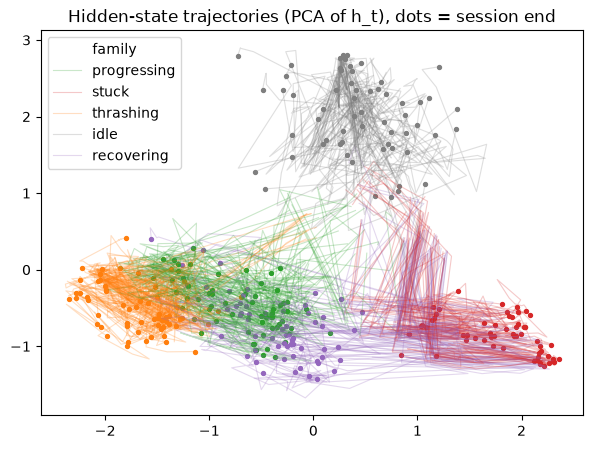

In [10]:
H = np.concatenate(hidden); pca = PCA(2).fit(H)
colours = dict(zip(FAMILIES, ["tab:green", "tab:red", "tab:orange", "tab:gray", "tab:purple"]))
plt.figure(figsize=(7, 5))
shown = set()
for h, f in zip(hidden, fam):
    z = pca.transform(h)
    plt.plot(z[:, 0], z[:, 1], "-", color=colours[f], alpha=0.25, lw=0.8,
             label=f if f not in shown else None)
    plt.scatter(z[-1, 0], z[-1, 1], color=colours[f], s=8)
    shown.add(f)
plt.legend(title="family"); plt.title("Hidden-state trajectories (PCA of h_t), dots = session end"); plt.show()

## 6. Gradient boosting (XGBoost-style)

### 6.1 The idea
The rules ranker proposes up to three candidate causes for a failed run. For
each of the 22 causes we train a **binary** model "is this the real cause?"
(one-vs-rest), then pick the best-scoring cause **among the rules' candidates**.
Inputs are 40 numbers: the 30 features, the GRU's 4 state scores and 6
cause-group scores.

### 6.2 The maths, step by step
Boosting builds an additive model $F(x) = \sum_m \eta\, f_m(x)$ where every
$f_m$ is a small regression tree and $\eta$ (0.2) shrinks each step. With
logistic loss and current margin $F$, $p = \sigma(F)$, each training row gets a
**gradient** and a **hessian**:

$$ g_i = p_i - y_i, \qquad h_i = p_i(1 - p_i). $$

A second-order Taylor expansion of the loss around $F$ makes the best weight of
a leaf containing rows $I$ a closed form, with L2 penalty $\lambda$:

$$ w^* = -\frac{G}{H + \lambda}, \qquad G = \sum_{i \in I} g_i,\; H = \sum_{i \in I} h_i. $$

Splitting a node into left/right is worth it when the **gain** is positive:

$$ \text{gain} = \tfrac12\left[\frac{G_L^2}{H_L + \lambda} + \frac{G_R^2}{H_R + \lambda} - \frac{G^2}{H + \lambda}\right] - \gamma. $$

`intel/src/booster.rs` implements exactly this, plus max depth (4), minimum
child weight (sum of $h \ge 1$), row/column subsampling, and split search over
32 quantile bins per feature (the "hist" method).

**Worked example.** Four rows, all with margin 0 so $p = 0.5$:
labels $y = [1, 1, 0, 0]$ give $g = [-0.5, -0.5, 0.5, 0.5]$, $h = [0.25]\times 4$.
A split that separates the two 1s from the two 0s, with $\lambda = 1$:
$G_L = -1, H_L = 0.5, G_R = 1, H_R = 0.5, G = 0, H = 1$, so
gain $= \tfrac12[1/1.5 + 1/1.5 - 0] = 0.667 > 0$ and the leaf weights are
$w_L = +0.667$, $w_R = -0.667$.

In [11]:
def grad_hess(y, margin):
    p = 1 / (1 + np.exp(-margin)); return p - y, p * (1 - p)
g, h = grad_hess(np.array([1, 1, 0, 0.]), np.zeros(4))
lam = 1.0
G, H, GL, HL, GR, HR = g.sum(), h.sum(), g[:2].sum(), h[:2].sum(), g[2:].sum(), h[2:].sum()
gain = 0.5 * (GL**2 / (HL + lam) + GR**2 / (HR + lam) - G**2 / (H + lam))
print(f"g={g}, h={h}\ngain={gain:.3f}, w_left={-GL / (HL + lam):+.3f}, w_right={-GR / (HR + lam):+.3f}")

g=[-0.5 -0.5  0.5  0.5], h=[0.25 0.25 0.25 0.25]
gain=0.667, w_left=+0.667, w_right=-0.667


### 6.3 A from-scratch booster (about 40 lines)
To prove the maths above is all there is, here is a minimal exact-greedy
booster and a check that it ranks like real `xgboost` with the same settings.

In [12]:
class Node:
    __slots__ = ("f", "thr", "left", "right", "w")

def build(X, g, h, depth, lam=1.0, gamma=0.0, min_child=1.0, max_depth=3):
    node = Node(); G, H = g.sum(), h.sum()
    node.w = -G / (H + lam); node.f = None
    if depth == max_depth or H < 2 * min_child:
        return node
    best = (0.0, None, None)
    for f in range(X.shape[1]):
        order = np.argsort(X[:, f]); xs = X[order, f]
        GL, HL = np.cumsum(g[order])[:-1], np.cumsum(h[order])[:-1]
        GR, HR = G - GL, H - HL
        ok = (xs[:-1] != xs[1:]) & (HL >= min_child) & (HR >= min_child)
        if not ok.any(): continue
        gain = 0.5 * (GL**2 / (HL + lam) + GR**2 / (HR + lam) - G**2 / (H + lam)) - gamma
        gain[~ok] = -np.inf; i = int(np.argmax(gain))
        if gain[i] > best[0]: best = (gain[i], f, (xs[i] + xs[i + 1]) / 2)
    if best[1] is None: return node
    node.f, node.thr = best[1], best[2]; m = X[:, node.f] <= node.thr
    node.left = build(X[m], g[m], h[m], depth + 1, lam, gamma, min_child, max_depth)
    node.right = build(X[~m], g[~m], h[~m], depth + 1, lam, gamma, min_child, max_depth)
    return node

def tree_predict(node, X):
    if node.f is None: return np.full(len(X), node.w)
    m = X[:, node.f] <= node.thr; out = np.empty(len(X))
    out[m] = tree_predict(node.left, X[m]); out[~m] = tree_predict(node.right, X[~m])
    return out

def boost(X, y, rounds=30, eta=0.2, **kw):
    margin, trees = np.zeros(len(X)), []
    for _ in range(rounds):
        g, h = grad_hess(y, margin); t = build(X, g, h, 0, **kw)
        margin += eta * tree_predict(t, X); trees.append(t)
    return lambda Z: sum(eta * tree_predict(t, Z) for t in trees)

In [13]:
@torch.no_grad()
def booster_rows(seqs):
    """One row per FAILED run: 30 features + GRU state scores (4) + group scores (6)."""
    rows, labels, cands, orders = [], [], [], []
    for seq in seqs:
        X, _, _ = tensors(seq)
        _, ls, lg, _ = model(X)
        ps, pg = ls[0].softmax(-1).numpy(), lg[0].softmax(-1).numpy()
        for t, e in enumerate(seq["events"]):
            if e["cause"] is None: continue
            rows.append(np.concatenate([e["x"], ps[t], pg[t]])); labels.append(e["cause"])
            cands.append(e["cands"]); orders.append(e["order"])
    return np.array(rows, np.float32), np.array(labels), cands, orders

Xtr, ytr, _, _ = booster_rows(train)
Xte, yte, cte, ote = booster_rows(test)
print(f"booster rows: train {len(Xtr)}, test {len(Xte)}, input dim {Xtr.shape[1]}")

# from scratch vs real xgboost on ONE binary task: "is the cause logic-wrong-on-case?"
k = CAUSES.index("logic-wrong-on-case")
yb_tr, yb_te = (ytr == k).astype(float), (yte == k).astype(float)
ours = boost(Xtr, yb_tr, rounds=30, eta=0.2, max_depth=3)
ref = xgb.train({"objective": "binary:logistic", "tree_method": "exact", "max_depth": 3, "eta": 0.2,
                 "lambda": 1.0, "gamma": 0.0, "min_child_weight": 1.0, "base_score": 0.5},
                xgb.DMatrix(Xtr, label=yb_tr), num_boost_round=30)
m_ours, m_ref = ours(Xte), ref.predict(xgb.DMatrix(Xte), output_margin=True)
print(f"AUC from scratch {roc_auc_score(yb_te, m_ours):.3f} | xgboost {roc_auc_score(yb_te, m_ref):.3f} "
      f"| margin correlation {np.corrcoef(m_ours, m_ref)[0, 1]:.3f}")

booster rows: train 8122, test 2096, input dim 40


AUC from scratch 0.983 | xgboost 0.983 | margin correlation 1.000


### 6.4 The real thing: 22 one-vs-rest models, ranked within the rules' candidates
Same hyper-parameters as the Rust booster (`hist`, 32 bins, depth 4, eta 0.2,
lambda 1, 60 rounds, 0.9 row and column subsampling). For each failed run we
take the best-scoring cause **among the rules' candidates**, so the comparison
with the rules is fair. *Real-choice* cases are the ones with 2+ candidates:
the only ones where the order matters.

In [14]:
params = {"objective": "binary:logistic", "tree_method": "hist", "max_bin": 32, "max_depth": 4, "eta": 0.2,
          "lambda": 1.0, "gamma": 0.0, "min_child_weight": 1.0, "subsample": 0.9, "colsample_bytree": 0.9,
          "seed": SEED, "verbosity": 0}
margins = np.full((len(Xte), len(CAUSES)), -np.inf)
models = {}
dte = xgb.DMatrix(Xte, feature_names=FEATURES + [f"gru_state_{s}" for s in STATES] + [f"gru_group_{g}" for g in GROUPS])
for c in range(len(CAUSES)):
    yc = (ytr == c).astype(np.float32)
    if yc.sum() == 0: continue
    dtr = xgb.DMatrix(Xtr, label=yc, feature_names=dte.feature_names)
    models[c] = xgb.train(params, dtr, num_boost_round=60)
    margins[:, c] = models[c].predict(dte, output_margin=True)

rules_top = np.array([o[0] for o in ote])
boost_top = np.array([max(c, key=lambda k: margins[i, k]) for i, c in enumerate(cte)])
multi = np.array([len(c) > 1 for c in cte])
def top1(pred, mask=None):
    m = np.ones(len(yte), bool) if mask is None else mask
    return (pred[m] == yte[m]).mean()
print(f"cases {len(yte)}, real-choice cases {multi.sum()}")
print(f"top-1                rules {top1(rules_top):.3f} | booster {top1(boost_top):.3f}")
print(f"real-choice top-1    rules {top1(rules_top, multi):.3f} | booster {top1(boost_top, multi):.3f}")
print(f"macro-F1             rules {f1_score(yte, rules_top, average='macro'):.3f} | "
      f"booster {f1_score(yte, boost_top, average='macro'):.3f}")

cases 2096, real-choice cases 856
top-1                rules 0.992 | booster 0.968
real-choice top-1    rules 0.981 | booster 0.921
macro-F1             rules 0.995 | booster 0.892


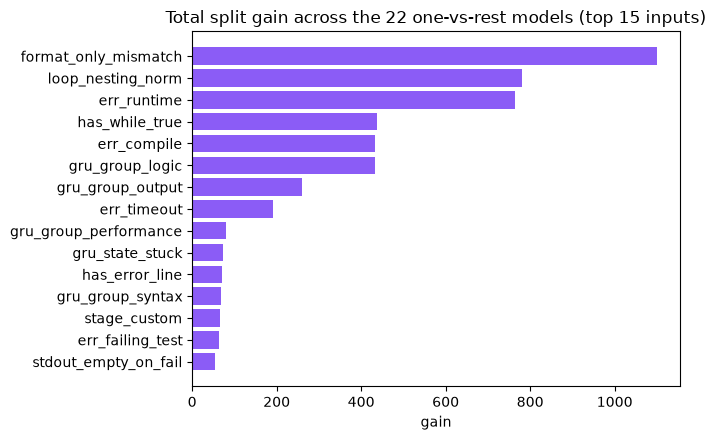

In [15]:
gain = {}
for c, m in models.items():
    for f, v in m.get_score(importance_type="gain").items():
        gain[f] = gain.get(f, 0) + v
top = sorted(gain.items(), key=lambda kv: -kv[1])[:15]
plt.figure(figsize=(7, 4.5))
plt.barh([f for f, _ in top][::-1], [v for _, v in top][::-1], color="#8b5cf6")
plt.title("Total split gain across the 22 one-vs-rest models (top 15 inputs)"); plt.xlabel("gain")
plt.tight_layout(); plt.show()

**Reading the result.** The rules read things the feature vector cannot (the
exception type straight from stderr, the printed output). Where the evidence
*is* in the features, the booster learns the same rules back. On these scripted
scenarios it usually ties or loses to the rules on the real-choice cases, which
is exactly what the Rust training run found (rules 0.964 vs booster 0.899
real-choice top-1). That outcome is the reason for section 7.

## 7. Shadow mode: when may a model override the rules?

LogiStream's `diagnose` node always keeps the rules' order. The booster's score
for each candidate is attached for display, but it may **reorder** the
candidates only if `metrics-v0.json` says it beat the rules on held-out
real-choice cases. The same gate, in four lines:

In [16]:
promoted = top1(boost_top, multi) > top1(rules_top, multi)
print("booster real-choice top-1 %.3f vs rules %.3f -> %s" % (
    top1(boost_top, multi), top1(rules_top, multi),
    "PROMOTED: may reorder" if promoted else "SHADOW: scores shown, rules keep the order"))

booster real-choice top-1 0.921 vs rules 0.981 -> SHADOW: scores shown, rules keep the order


Even when promoted, the booster may only **reorder the rules' own candidates**:
it can never add a cause the rules did not find, so every hint still points at
quoted evidence. If the sidecar is down or its files are missing, LogiStream
falls back to `rules-v1` within a 2-second timeout and tutoring is unaffected.

## 8. How this maps to the Rust code, and what is new

| This notebook | Rust (`intel/`) | Notes |
|---|---|---|
| `FEATURES`, `group_of` | `src/features.rs` | schema checked against `intel/tests/golden_v1.json` |
| `session()` scenarios | `src/synth.rs` | same five families; this is a compact re-implementation, so numbers differ slightly |
| `TemporalGRU`, truncated BPTT | `src/gru.rs` (burn 0.18, NdArray CPU) | hidden 32, window 8, Adam |
| `grad_hess`, `build`, `boost` | `src/booster.rs` | adds 32-bin hist split search, subsampling, min child weight |
| xgboost comparison | `scripts/xgb_crosscheck.py` | Rust vs xgboost: 99.8 % top-1 agreement |
| shadow gate | `src/bin/serve.rs` + `metrics-v0.json` | `/v1/track`, `/v1/rank`, `promoted` flag |

**New in LogiStream** (see the project README for the full list): bring your
own problem, a screen-aware on-screen assistant that reads the problem and the
code the student is writing (local vision model, frames never stored), in-depth
storage of screen problems (examples, function signature, expected complexity,
suggested test inputs, every code version seen), temporal memory in the session
checkpoint, and this `intel` sidecar.

*Repository:* https://github.com/SachmanChadhaa/Logi_Stream